# Задача классификации
Датасет Titanic-Dataset: 
- целевая переменная — Survived 


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
from kagglehub import KaggleDatasetAdapter

%matplotlib inline
sns.set_theme(style="darkgrid")

file_path = "Titanic-Dataset.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "yasserh/titanic-dataset",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)


pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df.shape)
print(df.head())
print(df["Survived"].describe())

print("Количество пропусков в каждом столбце:")
display(df.isna().sum().to_frame(name="missing_values").T)
print(f"Количество полных дубликатов строк: {df.duplicated().sum()}")

(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
missing_values,0,0,0,0,0,177,0,0,0,0,687,2


Количество полных дубликатов строк: 0


Датасет содержит 891 объект. Много пропусков номера кабины, меньше - возраст и порт посадки

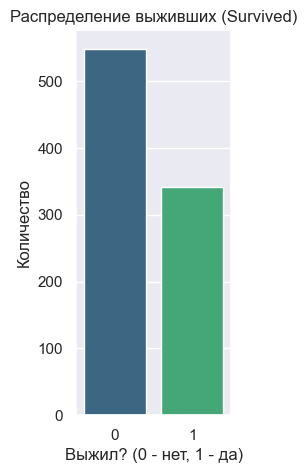

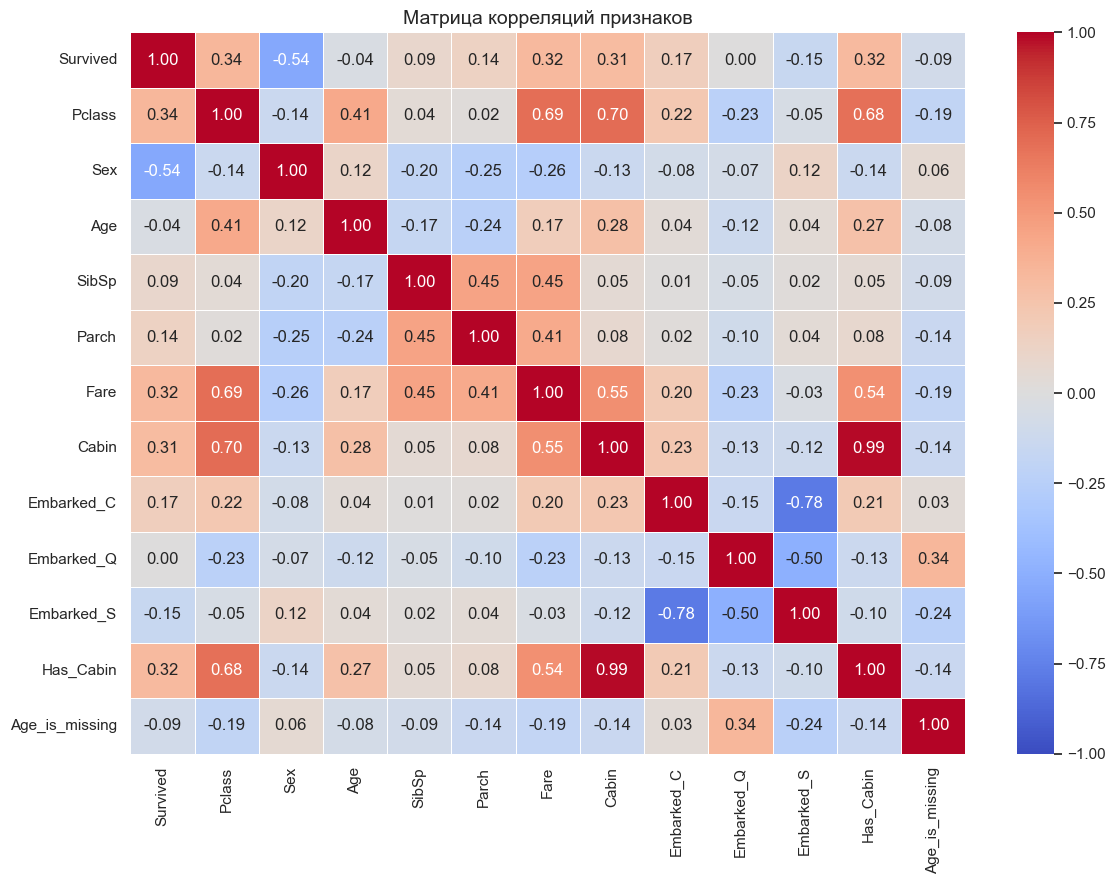

In [16]:
plt.figure(figsize=(2, 5))
ax = sns.countplot(data=df, x="Survived", hue="Survived", palette="viridis", legend=False)
plt.title("Распределение выживших (Survived)")
plt.xlabel("Выжил? (0 - нет, 1 - да)")
plt.ylabel("Количество")
plt.show()


df_filled = df.copy()


most_freq_port = df_filled['Embarked'].mode()[0]
df_filled['Embarked'] = df_filled['Embarked'].fillna(most_freq_port)
df_filled = pd.get_dummies(df_filled, columns=['Embarked'], drop_first=False, dtype=int)

df_filled['Sex'] = df['Sex'].map({'male': 1, 'female': 0})

df_filled['Pclass'] = df_filled['Pclass'].map({1: 3, 2: 2, 3: 1})

df_filled = df_filled.drop(columns=["Name", "Ticket", "PassengerId"])

df_filled['Has_Cabin'] = df_filled['Cabin'].notna().astype(int)
cabin_map_better_higher = {'A': 8, 'B': 7, 'C': 6, 'D': 5, 'E': 4, 'F': 3, 'G': 2, 'T': 1}
df_filled['Cabin'] = (df_filled['Cabin'].str[0].map(cabin_map_better_higher).fillna(0).astype(int))

df_filled['Age_is_missing'] = df_filled['Age'].isna().astype(int)
df_filled['Age'] = df_filled['Age'].fillna(df_filled.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

corr_matrix = df_filled.corr(method='spearman', numeric_only=True)
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title("Матрица корреляций признаков", fontsize=14)
plt.tight_layout()
plt.show()

Большинство погибло. Сильной корреляции с выживаемостью по каким-либо признакам не наблюдается.

In [20]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = df_filled.drop(columns=["Survived"])
y = df_filled["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y,
    random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(712, 12) (179, 12)


Подготовка данных для обучения и тестирования. Включена стратификация